In [1]:
import os, sys, json, re, random, unicodedata, copy, time, hashlib, platform
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfTransformer

import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset

# Có thể đặt biến môi trường để thay đổi cấu hình trước khi chạy notebook.
SEED = int(os.environ.get('DSS_SEED', '42'))
ENCODER_EPOCHS = int(os.environ.get('DSS_ENCODER_EPOCHS', '40'))
BATCH_SIZE = int(os.environ.get('DSS_BATCH_SIZE', '128'))
if min(ENCODER_EPOCHS, BATCH_SIZE) < 1:
    raise ValueError('Số vòng huấn luyện và kích thước batch phải lớn hơn 0.')

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def find_input(filename, env_name):
    explicit = os.environ.get(env_name)
    if explicit:
        path = Path(explicit).expanduser()
        if not path.is_file():
            raise FileNotFoundError(f'{env_name} không trỏ tới tệp hợp lệ: {path}')
        return path.resolve()
    for path in (Path.cwd() / 'data' / filename, Path.cwd() / filename):
        if path.is_file():
            return path.resolve()
    kaggle_input = Path('/kaggle/input')
    found = sorted(kaggle_input.rglob(filename)) if kaggle_input.exists() else []
    if len(found) == 1:
        return found[0].resolve()
    if len(found) > 1:
        raise ValueError(f'Có nhiều tệp {filename}; hãy đặt {env_name} để chọn một tệp.')
    raise FileNotFoundError(f'Không tìm thấy {filename}; hãy đặt {env_name}.')

DATA_PATH = find_input('dish_knowledge_base_with_images.json', 'DSS_DATA_PATH')
SYN_PATH = find_input('ingredients_synonyms_qwen.json', 'DSS_SYNONYMS_PATH')
MANUAL_SYNONYMS_PATH = find_input('manual_synonyms.json', 'DSS_MANUAL_SYNONYMS_PATH')
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
base = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path.cwd()
OUTPUT_DIR = Path(os.environ.get('DSS_OUTPUT_DIR', str(base / 'training_runs' / RUN_ID))).expanduser()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
protected_names = ['ingredient_set_encoder.pt', 'knowledge_graph.json',
                   'metrics.json', 'model_comparison.csv', 'model_comparison_charts.png',
                   'run_manifest.json', 'splits.json']
existing = [name for name in protected_names if (OUTPUT_DIR / name).exists()]
if existing:
    raise FileExistsError(f'Thư mục đầu ra đã có tệp {existing}; hãy chọn thư mục trống bằng DSS_OUTPUT_DIR.')

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

print(f'Môi trường: {DEVICE}; seed: {SEED}')
print(f'Dữ liệu món ăn: {DATA_PATH}')
print(f'Từ điển đồng nghĩa: {SYN_PATH}')
print(f'Từ điển thủ công: {MANUAL_SYNONYMS_PATH}')
print(f'Thư mục kết quả riêng: {OUTPUT_DIR.resolve()}')

Môi trường: cuda; seed: 42
Dữ liệu món ăn: /kaggle/input/datasets/phanchuc123/train306/dish_knowledge_base_with_images.json
Từ điển đồng nghĩa: /kaggle/input/datasets/phanchuc123/train306/ingredients_synonyms_qwen.json
Từ điển thủ công: /kaggle/input/datasets/phanchuc123/train306/manual_synonyms.json
Thư mục kết quả riêng: /kaggle/working/training_runs/20261125T012151786262Z


In [2]:
def normalize(value):
    s = unicodedata.normalize('NFKC', str(value or '')).lower().strip().replace('\u0111', 'd')
    s = ''.join(c for c in unicodedata.normalize('NFD', s) if unicodedata.category(c) != 'Mn')
    return re.sub(r'\s+', ' ', re.sub(r'[^a-z0-9 ]+', ' ', s)).strip()

# Read the manually curated rules from the same versioned data file on Kaggle or locally.
with open(MANUAL_SYNONYMS_PATH, 'r', encoding='utf-8') as f:
    manual_synonyms = json.load(f)
if not isinstance(manual_synonyms, dict):
    raise ValueError('manual_synonyms.json must contain a JSON object.')
for section in ('FOOD_SYNONYMS', 'SPICE_EXPANSIONS'):
    rules = manual_synonyms.get(section)
    if not isinstance(rules, dict) or not all(isinstance(k, str) and isinstance(v, str) and k and v for k, v in rules.items()):
        raise ValueError(f'{section} must contain non-empty string-to-string rules.')
FOOD_SYNONYMS = manual_synonyms['FOOD_SYNONYMS']
SPICE_EXPANSIONS = manual_synonyms['SPICE_EXPANSIONS']

synonym_to_canonical = dict(FOOD_SYNONYMS)
synonym_to_canonical.update(SPICE_EXPANSIONS)

if Path(SYN_PATH).exists():
    with open(SYN_PATH, 'r', encoding='utf-8') as f:
        syn_data = json.load(f)
    for item in syn_data:
        raw_ing = normalize(item.get('ingredient', ''))
        for syn in item.get('synonyms', []):
            s = normalize(syn)
            if not s or s == raw_ing: continue
            # Lọc bỏ hallucination của LLM (nước -> muối nở, vani...)
            if s in ('muoi no', 'bot no', 'vani nuoc') and not any(w in raw_ing for w in ('no', 'baking', 'vani')):
                continue
            if s in ('top mo hanh phi', 'nguyen lieu nuoc cham', 'ot chanh tac rau an kem'):
                continue
            if s in raw_ing or set(s.split()).issubset(set(raw_ing.split())):
                synonym_to_canonical[raw_ing] = s

# Tên chuẩn trong bảng thủ công không bị đề xuất tự động đổi sang tên khác.
# Các quy tắc thủ công được ưu tiên sau Qwen, rồi áp dụng gia vị như app.py.
for canonical in set(FOOD_SYNONYMS.values()) | set(SPICE_EXPANSIONS.values()):
    if canonical not in FOOD_SYNONYMS and canonical not in SPICE_EXPANSIONS:
        synonym_to_canonical.pop(canonical, None)
synonym_to_canonical.update(FOOD_SYNONYMS)
synonym_to_canonical.update(SPICE_EXPANSIONS)
print(f'✓ Đã xây dựng {len(synonym_to_canonical)} quy tắc ánh xạ từ đồng nghĩa.')

# Tập gia vị tủ bếp mặc định (Default Pantry Staples)
DEFAULT_PANTRY = {
    # Gia vị cơ bản.
    'muoi', 'muoi tinh', 'muoi hat', 'muoi iot', 'muoi bot',
    'duong', 'duong trang', 'duong cat', 'duong cat trang',
    'tieu', 'tieu xay', 'tieu bot', 'tieu den', 'tieu den xay',
    'hat tieu', 'hat tieu xay', 'tieu trang', 'tieu so',
    'toi', 'toi bam', 'cu toi', 'hanh', 'hanh tim', 'hanh kho', 'hanh cu',
    'ot', 'ot trai', 'ot bot', 'ot hiem',
    'hat nem', 'bot ngot', 'bot nem ga', 'mi chinh', 'bot canh', 'bot nem',

    # Nước, dầu và nước sốt thường dùng. Đây là các nguyên liệu được giả định sẵn có.
    'nuoc loc', 'nuoc', 'da vien', 'nuoc mam', 'nuoc mam ngon',
    'dau an', 'dau thuc vat', 'nuoc tuong', 'giam', 'dau hao', 'tuong ot', 'tuong ca',
}

# Web bổ sung các biến thể gia vị vào tập tủ bếp mặc định.
DEFAULT_PANTRY.update(SPICE_EXPANSIONS.keys())
# Công thức được lưu theo tên chuẩn, nên bổ sung cả tên chuẩn vào tủ bếp.
DEFAULT_PANTRY.update(SPICE_EXPANSIONS.values())

# Đọc và chuẩn hóa dữ liệu món ăn
with open(DATA_PATH, encoding='utf-8') as f: raw = json.load(f)
recipes, names = [], {}
for dish in raw:
    items = {}
    for ing in dish.get('ingredients', []):
        name = ing.get('name_vi', '')
        key = normalize(name)
        key = synonym_to_canonical.get(key, key) # Ánh xạ từ chuẩn
        if not key or not re.search('[a-z]', key): continue
        try: weight = float(ing.get('importance') or 1)
        except (ValueError, TypeError): weight = 1.0
        weight = min(3., max(1., weight))
        items[key] = max(items.get(key, 0), weight)
        names.setdefault(key, name)
    if len(items) >= 2:
        recipes.append({
            'id': dish.get('id'), 'name': dish.get('name_vi', ''), 'ingredients': items,
            'category': dish.get('category'), 'url': dish.get('url'), 'image_url': dish.get('image_url')
        })

vocab = {key: i + 1 for i, key in enumerate(sorted(names))} # 0 = padding
keys = [None] + sorted(names)
print(f"✓ Công thức hợp lệ: {len(recipes)} | Số nguyên liệu sau chuẩn hóa: {len(vocab)}")

weights = np.zeros((len(recipes), len(vocab)+1), dtype=np.float32)
for i, dish in enumerate(recipes):
    for key, w in dish['ingredients'].items(): weights[i, vocab[key]] = w
row_sums = np.maximum(weights.sum(axis=1), 1e-8)
recipe_ids = [np.flatnonzero(row).tolist() for row in weights]
bin_weights = (weights > 0).astype(np.float32)


✓ Đã xây dựng 1215 quy tắc ánh xạ từ đồng nghĩa.
✓ Công thức hợp lệ: 3253 | Số nguyên liệu sau chuẩn hóa: 3443


In [3]:
# Sinh truy vấn tủ lạnh và nhãn yếu; chia theo tập nguyên liệu chuẩn hóa.
from collections import defaultdict

QUERIES_PER_DISH = 12
MAX_ATTEMPTS_PER_DISH = 120
MIN_FOOD_COVERAGE = 0.5
MAX_MISSING_FOOD = 2
UNLABELED_WEIGHT = 0.02  # giả định giảm ảnh hưởng âm giả, không phải âm chắc chắn
rng = random.Random(SEED)
pantry_keys = {synonym_to_canonical.get(normalize(k), normalize(k)) for k in DEFAULT_PANTRY}
pantry_ids = {vocab[k] for k in pantry_keys if k in vocab}
aromatic_keys = {synonym_to_canonical.get(normalize(k), normalize(k)) for k in ('gung', 'hanh la', 'sa')}
aromatic_ids = {vocab[k] for k in aromatic_keys if k in vocab}

def candidate_food_presence(present):
    # Loại pantry. Nếu có thực phẩm ngoài rau gia vị, tìm ứng viên theo thực phẩm đó;
    # nếu chỉ có rau gia vị, vẫn tìm theo rau gia vị để không loại hết kết quả.
    food = present.copy()
    food[:, list(pantry_ids)] = 0
    without_aromatics = food.copy()
    without_aromatics[:, list(aromatic_ids)] = 0
    use_non_aromatic = np.any(without_aromatics > 0, axis=1)
    food[use_non_aromatic] = without_aromatics[use_non_aromatic]
    return food
# Ma trận nguyên liệu chính ước lượng, nhất quán với ứng dụng. Không có
# thực phẩm ngoài pantry thì không có nguyên liệu chính và main_score bằng 0.
food_mask = np.ones(len(vocab) + 1, dtype=bool)
food_mask[0] = False
food_mask[list(pantry_ids)] = False
food_weights = np.where(food_mask[None, :], weights, 0)
food_max = food_weights.max(axis=1, keepdims=True)
main_matrix = ((food_weights > 0) & (food_weights == food_max)).astype(np.float32)
main_count = main_matrix.sum(axis=1)
food_sets = [set(ids) - pantry_ids for ids in recipe_ids]
main_sets = []
food_recipes = defaultdict(set)
for label, food in enumerate(food_sets):
    if food:
        highest = max(weights[label, i] for i in food)
        main_sets.append({i for i in food if weights[label, i] == highest})
    else:
        main_sets.append(set())
    for ingredient_id in food:
        food_recipes[ingredient_id].add(label)

eligible_sources = [i for i, food in enumerate(food_sets) if food]
query_candidates = set()
for label in eligible_sources:
    food = sorted(food_sets[label])
    pantry = sorted(set(recipe_ids[label]) & pantry_ids)
    # Luôn giữ một nguyên liệu chính; có thể thêm thực phẩm từ món khác.
    # Neo hợp lệ bảo đảm mọi công thức có thực phẩm đều tạo ít nhất một nhãn.
    seen = {tuple(food)}
    for _ in range(MAX_ATTEMPTS_PER_DISH):
        anchor = rng.choice(sorted(main_sets[label]))
        others = [i for i in food if i != anchor]
        n_extra = rng.randint(0, len(others))
        query = {anchor, *rng.sample(others, n_extra)}
        if pantry and rng.random() < 0.25:
            query.add(rng.choice(pantry))
        if len(eligible_sources) > 1 and rng.random() < 0.5:
            other = rng.choice(eligible_sources)
            outside = sorted(food_sets[other] - query)
            if outside:
                query.update(rng.sample(outside, min(len(outside), rng.randint(1, 2))))
        seen.add(tuple(sorted(query)))
        if len(seen) >= QUERIES_PER_DISH:
            break
    query_candidates.update(seen)

def weak_labels(query):
    available = set(query) - pantry_ids
    candidate_labels = set()
    for ingredient_id in available:
        candidate_labels.update(food_recipes[ingredient_id])
    labels = []
    for label in candidate_labels:
        food = food_sets[label]
        matched = len(food & available)
        if (main_sets[label] & available and matched / len(food) >= MIN_FOOD_COVERAGE
                and len(food - available) <= MAX_MISSING_FOOD):
            labels.append(label)
    return tuple(sorted(labels))

groups = []
for query in sorted(query_candidates):
    labels = weak_labels(query)
    # Truy vấn không có nhãn yếu dương không thể dùng cho các chỉ số xếp hạng.
    if labels:
        groups.append((query, labels))
print(f'Bỏ {len(query_candidates) - len(groups)} truy vấn không đạt ngưỡng nhãn yếu.')
if len(groups) < 10:
    raise ValueError('Cần ít nhất 10 nhóm truy vấn để chia train/val/test 80:10:10.')
random.Random(SEED).shuffle(groups)
n_train, n_val = int(len(groups) * 0.8), int(len(groups) * 0.1)
splits = {'train': groups[:n_train], 'val': groups[n_train:n_train+n_val],
          'test': groups[n_train+n_val:]}
split_queries = {name: {query for query, _ in examples} for name, examples in splits.items()}
assert all(len(split_queries[name]) == len(examples) for name, examples in splits.items())
assert split_queries['train'].isdisjoint(split_queries['val'])
assert split_queries['train'].isdisjoint(split_queries['test'])
assert split_queries['val'].isdisjoint(split_queries['test'])
for name, examples in splits.items():
    multi_count = sum(len(labels) > 1 for _, labels in examples)
    print(f'Tập {name}: {len(examples)} nhóm | {multi_count} đa nhãn ({multi_count/len(examples):.1%})')
print(f'Tổng: {len(groups)} nhóm; không trùng chính xác giữa các tập.')
print('Cảnh báo: tỷ lệ đa nhãn là hệ quả ngưỡng tự động, không chứng minh nhãn đúng.')
one_food = [len(labels) for query, labels in groups if len(set(query) - pantry_ids) == 1]
if one_food:
    print(f'Truy vấn một thực phẩm: {len(one_food)}; số nhãn trung vị={np.median(one_food):.0f}, tối đa={max(one_food)}')
for example in (['muối'], ['thịt bò', 'tỏi', 'trứng'], ['thịt bò'], ['trứng'], ['cà chua']):
    ids = tuple(sorted({vocab[k] for k in (synonym_to_canonical.get(normalize(v), normalize(v)) for v in example) if k in vocab}))
    labels = weak_labels(ids) if ids else ()
    print(f'Kiểm tra nhãn yếu {example}: {len(labels)} món; ví dụ: {[recipes[i]["name"] for i in labels[:5]]}')
assert not weak_labels(tuple(sorted(pantry_ids)))
all_positive_labels = {label for _, labels in groups for label in labels}
assert set(eligible_sources).issubset(all_positive_labels)
print(f'Món không có thực phẩm ngoài tủ gia vị: {len(recipes) - len(eligible_sources)}; không có nhãn dương theo heuristic.')

class Queries(Dataset):
    def __init__(self, examples): self.examples = examples
    def __len__(self): return len(self.examples)
    def __getitem__(self, i): return self.examples[i]

def collate(batch):
    lengths = max(len(query) for query, _ in batch)
    x = torch.zeros((len(batch), lengths), dtype=torch.long)
    y = torch.zeros((len(batch), len(recipes)), dtype=torch.float32)
    for i, (query, labels) in enumerate(batch):
        x[i, :len(query)] = torch.tensor(query, dtype=torch.long)
        y[i, list(labels)] = 1.0
    return x, y

train_loader = DataLoader(Queries(splits['train']), batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate)
val_loader = DataLoader(Queries(splits['val']), batch_size=BATCH_SIZE, collate_fn=collate)
test_loader = DataLoader(Queries(splits['test']), batch_size=BATCH_SIZE, collate_fn=collate)


Bỏ 2680 truy vấn không đạt ngưỡng nhãn yếu.
Tập train: 27402 nhóm | 24593 đa nhãn (89.7%)
Tập val: 3425 nhóm | 3045 đa nhãn (88.9%)
Tập test: 3426 nhóm | 3077 đa nhãn (89.8%)
Tổng: 34253 nhóm; không trùng chính xác giữa các tập.
Cảnh báo: tỷ lệ đa nhãn là hệ quả ngưỡng tự động, không chứng minh nhãn đúng.
Truy vấn một thực phẩm: 903; số nhãn trung vị=1, tối đa=10
Kiểm tra nhãn yếu ['muối']: 0 món; ví dụ: []
Kiểm tra nhãn yếu ['thịt bò', 'tỏi', 'trứng']: 13 món; ví dụ: ['Nấm xào trứng', 'Bông điên điển xào thịt bò', 'Thịt kho tàu miền Bắc', 'Trứng chiên lòng đào', 'Trứng cuộn rong biển']
Kiểm tra nhãn yếu ['thịt bò']: 3 món; ví dụ: ['Bông điên điển xào thịt bò', 'Bò nướng mọi Củ Chi', 'Pad krapao (thịt bò xào lá hương nhu) kiểu Thái']
Kiểm tra nhãn yếu ['trứng']: 10 món; ví dụ: ['Nấm xào trứng', 'Thịt kho tàu miền Bắc', 'Trứng chiên lòng đào', 'Trứng cuộn rong biển', 'chiên trứng bằng nồi chiên không dầu']
Kiểm tra nhãn yếu ['cà chua']: 4 món; ví dụ: ['Nước ép bưởi cà chua', 'Nước ép cà

In [4]:
class IngredientSetEncoder(nn.Module):
    def __init__(self, n_ing, n_recipes, dim=96, hidden=192, dropout=0.2):
        super().__init__()
        self.embedding = nn.Embedding(n_ing + 1, dim, padding_idx=0)
        self.net = nn.Sequential(
            nn.Linear(dim, hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, n_recipes)
        )
    def forward(self, x):
        mask = (x != 0).unsqueeze(-1)
        pooled = (self.embedding(x) * mask).sum(1) / mask.sum(1).clamp(min=1)
        return self.net(pooled)  # logits độc lập cho từng món, không dùng softmax

EPOCHS, LR, PATIENCE = ENCODER_EPOCHS, 0.001, 4
model = IngredientSetEncoder(len(vocab), len(recipes)).to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)

# Tính trọng số chỉ từ train để giảm mất cân bằng nhãn; chặn tối đa 100.
positive_counts = np.zeros(len(recipes), dtype=np.float32)
for _, labels in splits['train']:
    positive_counts[list(labels)] += 1
missing_train_labels = np.flatnonzero(positive_counts == 0)
if len(missing_train_labels):
    no_food = sum(not food_sets[i] for i in missing_train_labels)
    only_heldout = len(missing_train_labels) - no_food
    print(f'Cảnh báo: {len(missing_train_labels)} món không có nhãn dương train: '
          f'{no_food} món chỉ có nguyên liệu thuộc tủ gia vị, '
          f'{only_heldout} món có nhãn nhưng chỉ vào validation/test do chia ngẫu nhiên.')
    print('Lớp không có dương train không được học đầy đủ; không dùng test để chuyển nhóm.')
positive_weights = np.clip(
    UNLABELED_WEIGHT * (len(splits['train']) - positive_counts) / np.maximum(positive_counts, 1), 1, 100
)
element_loss = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(positive_weights, device=DEVICE), reduction='none')
def loss_fn(logits, targets):
    # Nhãn chưa biết vẫn bị kéo nhẹ về 0; đây không phải positive-unlabeled learning đầy đủ.
    confidence = torch.where(targets > 0, 1.0, UNLABELED_WEIGHT)
    return (element_loss(logits, targets) * confidence).mean()
best_loss, best_state, stale = float('inf'), None, 0
train_loss_history, val_loss_history = [], []

print('=== BẮT ĐẦU HUẤN LUYỆN ĐA NHÃN ===')
for epoch in range(1, EPOCHS + 1):
    model.train(); total = count = 0
    for x, y in train_loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad(); loss = loss_fn(model(x), y); loss.backward(); optimizer.step()
        total += loss.item() * len(y); count += len(y)

    model.eval(); val_total = val_count = 0
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            val_total += loss_fn(model(x), y).item() * len(y); val_count += len(y)

    tl = total / count; vl = val_total / val_count
    train_loss_history.append(tl); val_loss_history.append(vl)
    print(f'Epoch {epoch:02d} | Train BCE: {tl:.4f} | Val BCE: {vl:.4f}')
    if vl < best_loss - 1e-4:
        best_loss, best_state, stale = vl, copy.deepcopy(model.state_dict()), 0
    else:
        stale += 1
        if stale >= PATIENCE:
            print(f'-> Early stopping tại epoch {epoch} (Best Val BCE: {best_loss:.4f})')
            break

model.load_state_dict(best_state)


Cảnh báo: 15 món không có nhãn dương train: 5 món chỉ có nguyên liệu thuộc tủ gia vị, 10 món có nhãn nhưng chỉ vào validation/test do chia ngẫu nhiên.
Lớp không có dương train không được học đầy đủ; không dùng test để chuyển nhóm.
=== BẮT ĐẦU HUẤN LUYỆN ĐA NHÃN ===
Epoch 01 | Train BCE: 0.0233 | Val BCE: 0.0207
Epoch 02 | Train BCE: 0.0162 | Val BCE: 0.0160
Epoch 03 | Train BCE: 0.0108 | Val BCE: 0.0121
Epoch 04 | Train BCE: 0.0067 | Val BCE: 0.0093
Epoch 05 | Train BCE: 0.0043 | Val BCE: 0.0076
Epoch 06 | Train BCE: 0.0029 | Val BCE: 0.0065
Epoch 07 | Train BCE: 0.0021 | Val BCE: 0.0059
Epoch 08 | Train BCE: 0.0016 | Val BCE: 0.0056
Epoch 09 | Train BCE: 0.0013 | Val BCE: 0.0054
Epoch 10 | Train BCE: 0.0011 | Val BCE: 0.0053
Epoch 11 | Train BCE: 0.0009 | Val BCE: 0.0053
Epoch 12 | Train BCE: 0.0008 | Val BCE: 0.0053
Epoch 13 | Train BCE: 0.0007 | Val BCE: 0.0054
-> Early stopping tại epoch 13 (Best Val BCE: 0.0054)


<All keys matched successfully>

In [5]:
def features_batch(x):
    present = np.zeros((len(x), len(vocab)+1), dtype=np.float32)
    for i, row in enumerate(x.cpu().numpy()): present[i, row[row != 0]] = 1
    matched_all = present @ (weights > 0).astype(np.float32).T
    coverage = matched_all / np.maximum(present.sum(axis=1, keepdims=True), 1)
    # Đồng bộ lọc ứng viên với app, gồm fallback cho truy vấn chỉ có rau gia vị.
    food_present = candidate_food_presence(present)
    matched = food_present @ (weights > 0).astype(np.float32).T
    cbf = (present @ weights.T) / row_sums[None, :]
    main_score = np.divide(present @ main_matrix.T, main_count[None, :],
                           out=np.zeros((len(x), len(recipes)), dtype=np.float32),
                           where=main_count[None, :] > 0)
    with torch.no_grad(): logits = model(x.to(DEVICE)).cpu().numpy()
    lo, hi = logits.min(axis=1, keepdims=True), logits.max(axis=1, keepdims=True)
    deep = (logits-lo) / np.maximum(hi-lo, 1e-8)
    return deep, cbf, coverage, main_score, matched

def collect_features(loader):
    model.eval(); feature_parts = []; labels = []
    for x, y in loader:
        feature_parts.append(features_batch(x)); labels.append(y.numpy())
    return tuple(np.concatenate([part[i] for part in feature_parts]) for i in range(5)), np.concatenate(labels)

# Các chỉ số macro: tính theo từng truy vấn rồi lấy trung bình.
def compute_metrics(scores, matched, labels, ks=(1, 5, 10)):
    if scores.shape != matched.shape or scores.shape != labels.shape:
        raise ValueError('Scores, matched và nhãn đa nhãn phải cùng kích thước.')
    relevant_counts = labels.sum(axis=1).astype(np.int64)
    if np.any(relevant_counts == 0):
        raise ValueError('Mỗi truy vấn phải có ít nhất một nhãn dương.')
    candidate_scores = np.where(matched > 0, scores, -np.inf)
    max_k = min(max(ks), scores.shape[1])
    ranking = np.argsort(-candidate_scores, axis=1, kind='stable')[:, :max_k]
    rows = np.arange(len(labels))[:, None]
    ranked_relevant = (labels[rows, ranking] > 0) & (matched[rows, ranking] > 0)
    metrics = {}
    for k in ks:
        hits = ranked_relevant[:, :k]
        n_hits = hits.sum(axis=1)
        discounts = 1.0 / np.log2(np.arange(2, k + 2))
        dcg = (hits * discounts[:hits.shape[1]]).sum(axis=1)
        ideal_prefix = np.concatenate(([0.0], np.cumsum(discounts)))
        ideal_dcg = ideal_prefix[np.minimum(relevant_counts, k)]
        metrics[f'Precision@{k}'] = float(np.mean(n_hits / k))
        metrics[f'Recall@{k}'] = float(np.mean(n_hits / relevant_counts))
        metrics[f'NDCG@{k}'] = float(np.mean(dcg / ideal_dcg))
        metrics[f'Hit@{k}'] = float(np.mean(n_hits > 0))
    return metrics

def evaluate_features(features, labels, coeff):
    deep, cbf, coverage, main, matched = features
    scores = coeff[0]*deep + coeff[1]*cbf + coeff[2]*coverage + coeff[3]*main
    return compute_metrics(scores, matched, labels)

# Chọn trọng số theo NDCG@10 trên validation; không dùng test để lựa chọn.
val_features, val_labels = collect_features(val_loader)
candidates = [(a/4, b/4, c/4, (4-a-b-c)/4)
              for a in range(5) for b in range(5-a) for c in range(5-a-b)]
validation_grid = [(evaluate_features(val_features, val_labels, coeff)['NDCG@10'], coeff)
                   for coeff in candidates]
best_score, best_coeff = max(validation_grid, key=lambda item: item[0])
val_selected = evaluate_features(val_features, val_labels, best_coeff)
print(f'Trọng số Hybrid: {best_coeff} | NDCG@10 validation: {best_score:.4f}')
# Ablation: mỗi cấu hình được chọn trên validation, không lựa chọn bằng test.
ablation_selected = {}
for index, feature_name in enumerate(('Deep', 'CBF', 'Coverage', 'Main')):
    eligible = [(score, coeff) for score, coeff in validation_grid if coeff[index] == 0]
    score, coeff = max(eligible, key=lambda item: item[0])
    ablation_selected[feature_name] = {'coeff': coeff, 'validation_ndcg10': score}
    print(f'Không {feature_name}: {coeff} | validation NDCG@10={score:.4f}')

# Các mô hình được đánh giá trên cùng các nhóm truy vấn test.
test_features, test_labels = collect_features(test_loader)
deep, cbf, coverage, main, matched = test_features
tfidf_trans = TfidfTransformer(norm='l2')
recipe_tfidf = tfidf_trans.fit_transform(bin_weights).toarray()
test_queries = [row[row != 0] for x, _ in test_loader for row in x.cpu().numpy()]
N_test = len(test_queries)
Q_mat = np.zeros((N_test, len(vocab) + 1), dtype=np.float32)
for i, query in enumerate(test_queries): Q_mat[i, query] = 1.0

CHUNK = 1000
jaccard_all, tfidf_all = [], []
d_lens = bin_weights.sum(axis=1, keepdims=True).T
for start in range(0, N_test, CHUNK):
    sub_q = Q_mat[start:start + CHUNK]
    sub_inter = sub_q @ bin_weights.T
    sub_union = sub_q.sum(axis=1, keepdims=True) + d_lens - sub_inter
    jaccard_all.append(sub_inter / np.maximum(sub_union, 1e-8))
    sub_tfidf_q = tfidf_trans.transform(sub_q).toarray()
    tfidf_all.append(sub_tfidf_q @ recipe_tfidf.T)

jaccard_scores = np.concatenate(jaccard_all, axis=0)
tfidf_scores = np.concatenate(tfidf_all, axis=0)
random_scores = np.random.default_rng(SEED).random(matched.shape, dtype=np.float32)
results_dict = {
    '1. Random Matching': compute_metrics(random_scores, matched, test_labels),
    '2. CBF (Importance Weighted)': evaluate_features(test_features, test_labels, (0, 1, 0, 0)),
    '3. TF-IDF + Cosine': compute_metrics(tfidf_scores, matched, test_labels),
    '4. Jaccard Similarity (IoU)': compute_metrics(jaccard_scores, matched, test_labels),
    '5. Ingredient Set Encoder': evaluate_features(test_features, test_labels, (1, 0, 0, 0)),
    '6. Previous Hybrid (50/50)': evaluate_features(test_features, test_labels, (0.5, 0.5, 0, 0)),
    '7. Main-aware Equal Blend': evaluate_features(test_features, test_labels, (0.25, 0.25, 0.25, 0.25)),
    '8. Deep Hybrid (validation selected)': evaluate_features(test_features, test_labels, best_coeff),
}
for feature_name, config in ablation_selected.items():
    results_dict[f'Ablation không {feature_name}'] = evaluate_features(test_features, test_labels, config['coeff'])
df_comparison = pd.DataFrame(results_dict).T
print('\n=== ĐÁNH GIÁ TEST THEO NHÃN YẾU (nhãn chưa gán được coi không liên quan) ===')
print(df_comparison.round(4).to_string())


Trọng số Hybrid: (0.75, 0.25, 0.0, 0.0) | NDCG@10 validation: 0.9163
Không Deep: (0.0, 1.0, 0.0, 0.0) | validation NDCG@10=0.6984
Không CBF: (1.0, 0.0, 0.0, 0.0) | validation NDCG@10=0.9069
Không Coverage: (0.75, 0.25, 0.0, 0.0) | validation NDCG@10=0.9163
Không Main: (0.75, 0.25, 0.0, 0.0) | validation NDCG@10=0.9163

=== ĐÁNH GIÁ TEST THEO NHÃN YẾU (nhãn chưa gán được coi không liên quan) ===
                                      Precision@1  Recall@1  NDCG@1   Hit@1  Precision@5  Recall@5  NDCG@5   Hit@5  Precision@10  Recall@10  NDCG@10  Hit@10
1. Random Matching                         0.0668    0.0217  0.0668  0.0668       0.0534    0.0688  0.0764  0.2353        0.0496     0.1163   0.0911  0.3908
2. CBF (Importance Weighted)               0.8692    0.1984  0.8692  0.8692       0.5649    0.4545  0.7349  0.9731        0.4298     0.5965   0.7079  0.9842
3. TF-IDF + Cosine                         0.7464    0.1799  0.7464  0.7464       0.4350    0.3896  0.5998  0.9434        0.3153   

Saved chart: /kaggle/working/training_runs/20261125T012151786262Z/model_comparison_charts.png


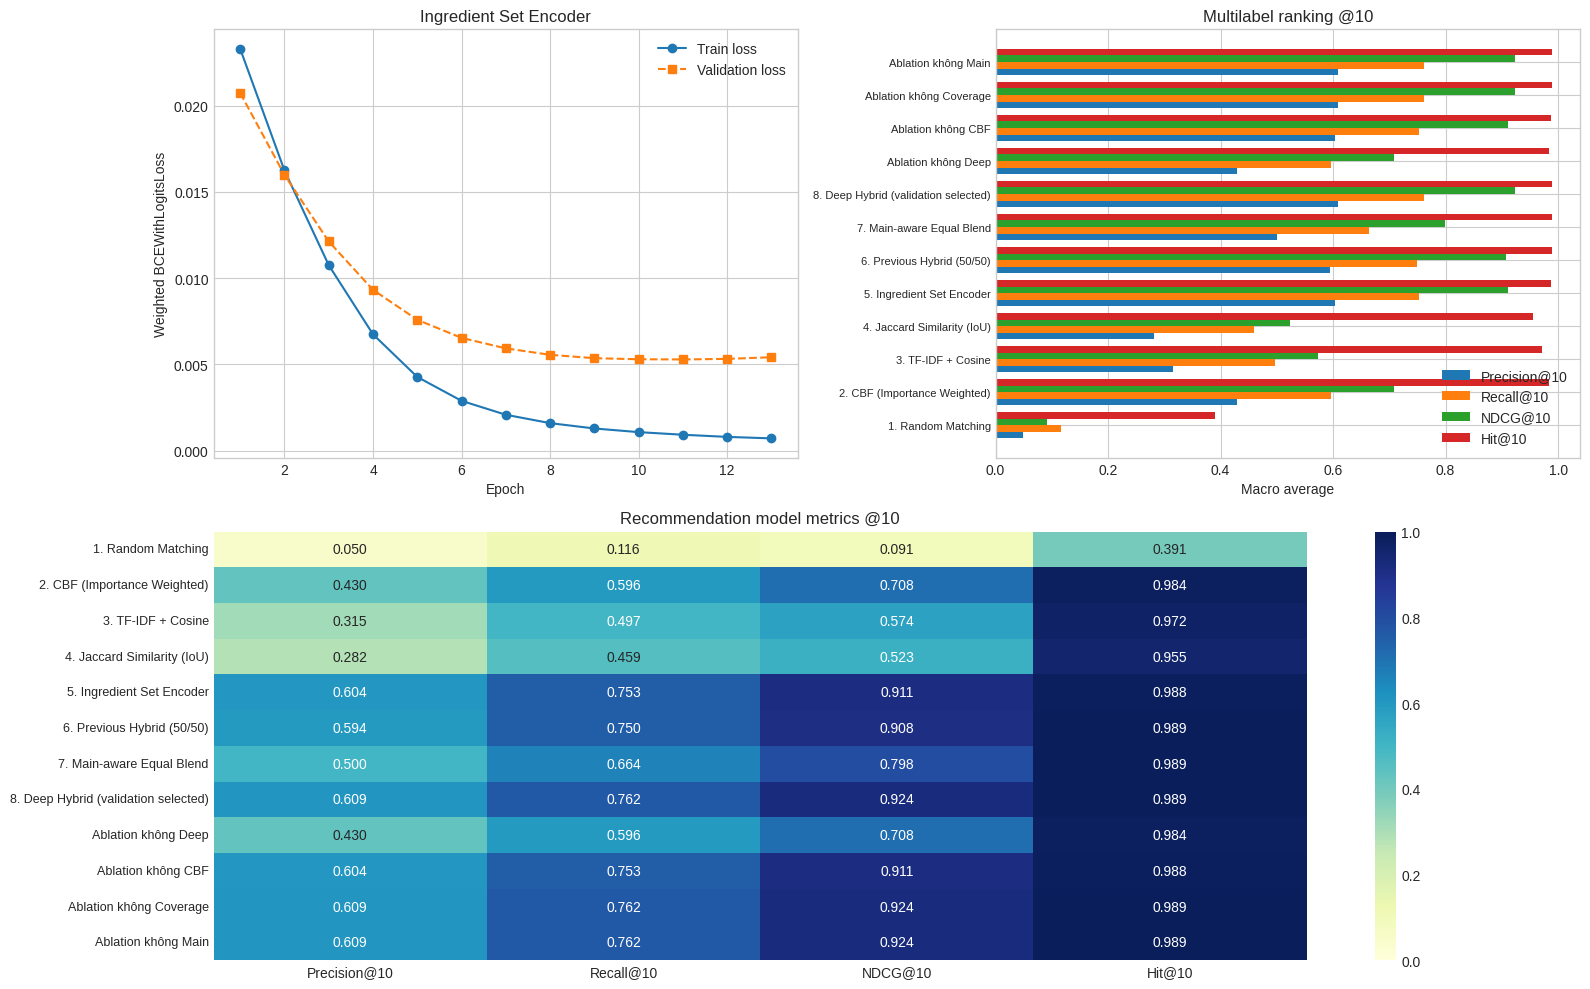

In [6]:
# Biểu đồ so sánh các chỉ số đa nhãn tại K=10.
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig = plt.figure(figsize=(16, 10))
ax1 = plt.subplot(2, 2, 1)
epochs_range = range(1, len(train_loss_history) + 1)
ax1.plot(epochs_range, train_loss_history, 'o-', label='Train loss')
ax1.plot(epochs_range, val_loss_history, 's--', label='Validation loss')
ax1.set_title('Ingredient Set Encoder'); ax1.set_xlabel('Epoch')
ax1.set_ylabel('Weighted BCEWithLogitsLoss'); ax1.legend(); ax1.grid(True)
ax2 = plt.subplot(2, 2, 2)
models = list(df_comparison.index); x_pos = np.arange(len(models)); width = 0.2
for offset, metric in zip((-1.5, -0.5, 0.5, 1.5), ('Precision@10', 'Recall@10', 'NDCG@10', 'Hit@10')):
    ax2.barh(x_pos + offset * width, df_comparison[metric], width, label=metric)
ax2.set_yticks(x_pos); ax2.set_yticklabels(models, fontsize=8)
ax2.set_xlabel('Macro average'); ax2.set_title('Multilabel ranking @10')
ax2.legend(loc='lower right'); ax2.grid(True, axis='x')
ax3 = plt.subplot(2, 2, (3, 4))
criteria_matrix = df_comparison[['Precision@10', 'Recall@10', 'NDCG@10', 'Hit@10']]
sns.heatmap(criteria_matrix, annot=True, fmt='.3f', cmap='YlGnBu', vmin=0, vmax=1, ax=ax3)
ax3.set_title('Recommendation model metrics @10'); ax3.set_yticklabels(criteria_matrix.index, rotation=0, fontsize=9)
plt.tight_layout(); chart_path = OUTPUT_DIR / 'model_comparison_charts.png'
plt.savefig(chart_path, dpi=300, bbox_inches='tight'); print(f'Saved chart: {chart_path}'); plt.show()


In [7]:
# Xây dựng đồ thị và đối chiếu luồng gợi ý với app.py.
from collections import defaultdict

kg = defaultdict(list); inv_kg = defaultdict(list)
for d in recipes:
    did = d['id']
    for ing_name, imp in d['ingredients'].items():
        kg[did].append({'rel': 'requires', 'target': ing_name, 'importance': imp})
        inv_kg[ing_name].append({'rel': 'required_by', 'target': did, 'importance': imp})
    if d['category']:
        kg[did].append({'rel': 'category', 'target': d['category']})
        inv_kg[d['category']].append({'rel': 'category_of', 'target': did})
recipe_idx_by_id = {d['id']: i for i, d in enumerate(recipes)}

def graph_candidates(ingredient_ids, category=None):
    candidates = set()
    for iid in ingredient_ids:
        for edge in inv_kg.get(keys[iid], []):
            if edge['target'] in recipe_idx_by_id:
                candidates.add(recipe_idx_by_id[edge['target']])
    if category:
        category_matches = {recipe_idx_by_id[e['target']] for e in inv_kg.get(category, [])
                            if e['target'] in recipe_idx_by_id}
        candidates &= category_matches
    return candidates

def graph_explanation(dish_idx, user_ing_ids):
    dish = recipes[dish_idx]
    user_keys = {keys[i] for i in user_ing_ids}
    matched, missing = [], []
    for edge in kg.get(dish['id'], []):
        if edge.get('rel') == 'requires':
            name = edge.get('target')
            item = {'name': names.get(name, name), 'importance': edge.get('importance', 1)}
            (matched if name in user_keys else missing).append(item)
    return {'matched': matched, 'missing': missing, 'category': dish.get('category')}

def recommend(ingredients, top_k=10, method='hybrid', category=None, assume_pantry=True):
    if isinstance(ingredients, str):
        raw_items = [s.strip() for s in ingredients.split(',') if s.strip()]
    else:
        raw_items = [str(s).strip() for s in ingredients if str(s).strip()]
    resolved = [synonym_to_canonical.get(normalize(s), normalize(s)) for s in raw_items]
    unknown = [raw_items[i] for i, key in enumerate(resolved) if key not in vocab]
    ids = sorted({vocab[key] for key in resolved if key in vocab})
    optional = pantry_keys if assume_pantry else set()
    available_food_ids = {i for i in ids if i not in pantry_ids}
    non_aromatic_food_ids = available_food_ids - aromatic_ids
    food_ids = non_aromatic_food_ids or available_food_ids
    result = {'ready': [], 'needs_shopping': [], 'unknown': unknown,
              'query_resolved': [names.get(keys[i], keys[i]) for i in ids], 'notice': None}
    if not ids:
        result['notice'] = 'Chưa nhận diện được nguyên liệu. Hãy kiểm tra tên và nhập thêm nguyên liệu thực phẩm.'
        return result
    if not food_ids:
        result['notice'] = 'Bạn mới nhập gia vị hoặc nguyên liệu tủ bếp. Hãy thêm nguyên liệu thực phẩm như thịt, trứng hoặc rau.'
        return result

    x = torch.tensor([ids])
    deep, cbf, coverage, main, matched = features_batch(x)
    configs = {'hybrid': best_coeff, 'cbf': (0, 1, 0, 0),
               'encoder': (1, 0, 0, 0), 'main_aware': (0.25, 0.25, 0.25, 0.25)}
    coeff = configs.get(method, best_coeff)
    scores = sum(w * feature[0] for w, feature in zip(coeff, (deep, cbf, coverage, main)))
    candidates = graph_candidates(food_ids, category=category if category != 'all' else None)
    if not candidates:
        result['notice'] = 'Không tìm thấy món khớp nguyên liệu thực phẩm và loại món đã chọn. Hãy thử thêm nguyên liệu hoặc đổi loại món.'
    for idx in np.argsort(-scores):
        if idx not in candidates:
            continue
        dish = recipes[idx]
        have = set(ids)
        missing_keys = [k for k in dish['ingredients'] if vocab.get(k) not in have]
        missing_required = [k for k in missing_keys if k not in optional]
        explanation = graph_explanation(idx, ids)
        group = 'ready' if not missing_required else 'needs_shopping'
        result[group].append({
            'dish_id': dish['id'], 'dish': dish['name'],
            'score': round(float(scores[idx]), 4),
            'score_percent': int(min(100, max(0, float(scores[idx]) * 100))),
            'matched': [names.get(k, k) for k in dish['ingredients'] if vocab.get(k) in have],
            'missing_required': [names.get(k, k) for k in missing_required],
            'missing_optional': [names.get(k, k) for k in missing_keys if k in optional],
            'missing_main_provisional': [names.get(k, k) for k in missing_required
                                         if vocab.get(k) is not None and main_matrix[idx, vocab[k]] > 0],
            'input_utilization': round(float(coverage[0, idx]) * 100, 1),
            'matched_food_count': sum(vocab.get(k) in food_ids for k in dish['ingredients']),
            'food_utilization': round(100 * sum(vocab.get(k) in food_ids for k in dish['ingredients']) / len(food_ids), 1),
            'category': explanation.get('category', 'Khác'), 'kg_explanation': explanation,
            'url': dish.get('url'),
            'image_url': dish.get('image_url') or 'https://images.unsplash.com/photo-1546069901-ba9599a7e63c?auto=format&fit=crop&w=400&q=80'
        })
    for group in ('ready', 'needs_shopping'):
        result[group].sort(key=lambda item: (
            -item['matched_food_count'], len(item['missing_main_provisional']),
            len(item['missing_required']), -item['score']))
    result['ready'] = result['ready'][:top_k]
    result['needs_shopping'] = result['needs_shopping'][:top_k]
    return result

sample_q = ['thịt heo', 'cà chua', 'hành tây']
res_test = recommend(sample_q, top_k=3, method='hybrid', assume_pantry=True)
print(f'\n=== GỢI Ý THỬ VỚI: {sample_q} ===')
for group in ('ready', 'needs_shopping'):
    print(group.upper() + ':')
    for result in res_test[group]:
        print(f"  - {result['dish']} (score: {result['score']}, tận dụng: {result['input_utilization']}%)")
print('Chưa nhận diện:', res_test['unknown'])
# Đánh giá end-to-end trên nhãn yếu, không phải đánh giá bởi người dùng.
# Mỗi nhóm chỉ tính metric trên truy vấn có ít nhất một nhãn yếu trong nhóm đó.
# Nhãn và quy tắc chia nhóm cùng dựa vào công thức: đặc biệt điểm ready có thể gần như tất yếu,
# không chứng minh chất lượng đối với người dùng. Cần kiểm thử do con người gán nhãn độc lập.
def evaluate_end_to_end(ks=(1, 5, 10)):
    pantry_mask = np.zeros(len(vocab) + 1, dtype=bool)
    pantry_mask[list(pantry_ids)] = True
    food_recipe = bin_weights.copy()
    food_recipe[:, pantry_mask] = 0
    query_food = Q_mat.copy()
    query_food[:, pantry_mask] = 0
    # Candidate/rank dùng tập lọc; thiếu bắt buộc vẫn xét mọi thực phẩm đã nhập,
    # kể cả gừng, hành lá, sả: chúng không được tự giả định có sẵn trong pantry.
    food_matches = candidate_food_presence(Q_mat) @ food_recipe.T
    missing_food = food_recipe.sum(axis=1)[None, :] - query_food @ food_recipe.T
    main_required = main_matrix
    missing_main = main_required.sum(axis=1)[None, :] - Q_mat @ main_required.T
    scores = sum(w * f for w, f in zip(best_coeff, test_features[:4]))
    report = {}
    for name in ('ready', 'needs_shopping'):
        values = {f'{metric}@{k}': [] for k in ks for metric in ('Precision', 'Recall', 'NDCG', 'Hit')}
        no_results = eligible = 0
        for row in range(len(test_labels)):
            group = (missing_food[row] == 0) if name == 'ready' else (missing_food[row] > 0)
            candidate = group & (food_matches[row] > 0)
            no_results += int(not np.any(candidate))
            relevant = group & (test_labels[row] > 0)
            n_relevant = int(relevant.sum())
            if not n_relevant:
                continue
            eligible += 1
            indices = np.flatnonzero(candidate)
            order = np.lexsort((-scores[row, indices], missing_food[row, indices],
                                missing_main[row, indices], -food_matches[row, indices]))
            hits = relevant[indices[order[:max(ks)]]]
            for k in ks:
                top = hits[:k]
                count = int(top.sum())
                discount = 1.0 / np.log2(np.arange(2, k + 2))
                dcg = float((top * discount[:len(top)]).sum())
                ideal = float(discount[:min(n_relevant, k)].sum())
                values[f'Precision@{k}'].append(count / k)
                values[f'Recall@{k}'].append(count / n_relevant)
                values[f'NDCG@{k}'].append(dcg / ideal)
                values[f'Hit@{k}'].append(float(count > 0))
        report[name] = {'queries_with_group_label': eligible, 'queries_total': len(test_labels),
                        'empty_result_fraction': no_results / len(test_labels),
                        'metrics': {key: float(np.mean(value)) if value else None
                                    for key, value in values.items()}}
    return report

end_to_end_metrics = evaluate_end_to_end()
print('\n=== END-TO-END THEO NHÃN YẾU (chưa gán coi không liên quan; có tủ gia vị) ===')
for group, result in end_to_end_metrics.items():
    print(group, result)



=== GỢI Ý THỬ VỚI: ['thịt heo', 'cà chua', 'hành tây'] ===
READY:
  - Thịt heo chiên tỏi ớt (score: 0.7861, tận dụng: 66.7%)
  - Nước ép cà chua không cần máy (score: 0.9125, tận dụng: 33.3%)
  - Nước ép cà chua (score: 0.8534, tận dụng: 33.3%)
NEEDS_SHOPPING:
  - mì spaghetti (score: 0.6609, tận dụng: 100.0%)
  - Cháo củ cải trắng (score: 0.7449, tận dụng: 66.7%)
  - Thịt bọc trứng cút sốt cà chua (score: 0.7153, tận dụng: 66.7%)
Chưa nhận diện: []

=== END-TO-END THEO NHÃN YẾU (chưa gán coi không liên quan; có tủ gia vị) ===
ready {'queries_with_group_label': 2508, 'queries_total': 3426, 'empty_result_fraction': 0.3260361938120257, 'metrics': {'Precision@1': 0.9206539074960127, 'Recall@1': 0.5215601645907022, 'NDCG@1': 0.9206539074960127, 'Hit@1': 0.9206539074960127, 'Precision@5': 0.4266347687400319, 'Recall@5': 0.8505905624537766, 'NDCG@5': 0.884843162182101, 'Hit@5': 0.9206539074960127, 'Precision@10': 0.2257974481658692, 'Recall@10': 0.8663848539270719, 'NDCG@10': 0.881509177005

In [8]:
# Xuất bộ kết quả của lần chạy hiện tại vào thư mục riêng.
print('=== XUẤT MÔ HÌNH VÀ KẾT QUẢ ===')
checkpoint = {
    'state_dict': model.state_dict(), 'vocab': vocab,
    'synonym_to_canonical': synonym_to_canonical, 'default_pantry': list(DEFAULT_PANTRY),
    'best_coeff': best_coeff, 'recipes': recipes, 'names': names, 'run_id': RUN_ID,
    'training_objective': 'BCEWithLogitsLoss', 'label_type': 'multilabel',
}
torch.save(checkpoint, OUTPUT_DIR / 'ingredient_set_encoder.pt')
with (OUTPUT_DIR / 'knowledge_graph.json').open('w', encoding='utf-8') as f:
    json.dump({'kg': kg, 'names': names, 'run_id': RUN_ID,
               'categories': sorted({d['category'] for d in recipes if d['category']})},
              f, ensure_ascii=False)

# Mỗi truy vấn chỉ xuất hiện ở một tập; recipe_indices là toàn bộ nhãn dương đã gán.
split_export = {name: [{'ingredient_ids': list(query), 'recipe_indices': list(labels)}
                       for query, labels in examples] for name, examples in splits.items()}
with (OUTPUT_DIR / 'splits.json').open('w', encoding='utf-8') as f:
    json.dump(split_export, f, ensure_ascii=False)
df_comparison.to_csv(OUTPUT_DIR / 'model_comparison.csv', encoding='utf-8-sig')

test_names = {
    '1. Random Matching': 'Random',
    '2. CBF (Importance Weighted)': 'CBF',
    '3. TF-IDF + Cosine': 'TF-IDF Cosine',
    '4. Jaccard Similarity (IoU)': 'Jaccard Similarity',
    '5. Ingredient Set Encoder': 'Encoder',
    '6. Previous Hybrid (50/50)': 'Previous hybrid 50/50',
    '7. Main-aware Equal Blend': 'Main-aware Equal Blend',
    '8. Deep Hybrid (validation selected)': 'Deep hybrid (validation selected)',
}
test_metrics = {output_name: results_dict[source_name] for source_name, output_name in test_names.items()}
run_info = {
    'id': RUN_ID, 'seed': SEED, 'device': str(DEVICE),
    'data_file': DATA_PATH.name, 'data_sha256': sha256_file(DATA_PATH),
    'synonyms_file': SYN_PATH.name, 'synonyms_sha256': sha256_file(SYN_PATH),
    'manual_synonyms_file': MANUAL_SYNONYMS_PATH.name, 'manual_synonyms_sha256': sha256_file(MANUAL_SYNONYMS_PATH),
    'splits_sha256': sha256_file(OUTPUT_DIR / 'splits.json'),
    'split_method': 'normalized ingredient query groups, random 80/10/10',
    'label_rule': 'weak positives: max-importance food match, >=50% food coverage, <=2 missing food ingredients; pantry excluded',
    'loss': 'BCEWithLogitsLoss; unlabeled weight 0.02, train-only per-class positive weights capped at 100',
    'selection_metric': 'validation NDCG@10',
    'candidate_filter': 'non-pantry non-aromatic food overlap; fallback to aromatic food when no other food is present',
    'metric_averaging': 'macro per query; binary relevance',
    'encoder_epochs_limit': ENCODER_EPOCHS, 'batch_size': BATCH_SIZE,
    'python': platform.python_version(), 'torch': str(torch.__version__),
    'numpy': np.__version__, 'pandas': pd.__version__,
}
metrics = {
    'selected_weights': [float(value) for value in best_coeff],
    'validation': val_selected, 'ablation_validation_selected': ablation_selected, 'test': test_metrics,
    'end_to_end_weak_labels': end_to_end_metrics,
    'ablation_test': {name: results_dict[f'Ablation không {name}'] for name in ablation_selected},
    'split_sizes': {name: len(examples) for name, examples in splits.items()},
    'missing_train_recipe_labels': int(len(missing_train_labels)),
    'missing_train_labels_no_food': int(sum(not food_sets[i] for i in missing_train_labels)),
    'missing_train_labels_only_heldout': int(sum(bool(food_sets[i]) for i in missing_train_labels)),
    'run': run_info,
}
with (OUTPUT_DIR / 'metrics.json').open('w', encoding='utf-8') as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2, allow_nan=False)

export_names = ['ingredient_set_encoder.pt', 'knowledge_graph.json',
                'splits.json', 'model_comparison.csv', 'metrics.json', 'model_comparison_charts.png']
manifest = {'run': run_info, 'files_sha256': {name: sha256_file(OUTPUT_DIR / name)
                                               for name in export_names if (OUTPUT_DIR / name).is_file()}}
with (OUTPUT_DIR / 'run_manifest.json').open('w', encoding='utf-8') as f:
    json.dump(manifest, f, ensure_ascii=False, indent=2, allow_nan=False)
print(f'Đã lưu kết quả của lần chạy {RUN_ID}: {OUTPUT_DIR.resolve()}')


=== XUẤT MÔ HÌNH VÀ KẾT QUẢ ===
Đã lưu kết quả của lần chạy 20261125T012151786262Z: /kaggle/working/training_runs/20261125T012151786262Z
